# 8. Hypothesis tests and goodness of fit

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 4 and 5

**Reading:** Taylor, ch. 5.8, 9 and 12 · Bevington & Robinson, ch. 4.4 and
11 · Fornasini, ch. 9 to 11 · Rouaud, ch. I.G and I.H

Error analysis constantly asks yes-or-no questions. Does the result agree
with theory? Do two laboratories agree? Are these readings normally
distributed? Does the fit need a quadratic term? Is there a correlation?
A **hypothesis test** turns such a question into a probability statement.
This chapter sets out the logic once and then applies it to the tests that
experimenters use most:

1. the logic of a test: null hypothesis, test statistic, $p$-value, and the
   two kinds of error;
2. comparing results: the $z$ and $t$ tests;
3. the $\chi^2$ test of a distribution;
4. the $F$ test, for comparing variances and for deciding whether a model
   needs another parameter;
5. the linear correlation coefficient;
6. what goes wrong when many tests are made.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(108)

## 8.1 The logic of a test

1. State a **null hypothesis** $H_0$, usually the "nothing new" option: the
   result agrees with theory, the two methods measure the same thing, the
   data are normal.
2. Choose a **test statistic** whose distribution is known if $H_0$ is true:
   for example $z = |x_1 - x_2|/\sqrt{u_1^2 + u_2^2}$, standard normal under
   $H_0$ (Section 1.6).
3. Compute the **$p$-value**: the probability, *if $H_0$ were true*, of a
   value of the statistic at least as extreme as the one observed.
4. If $p$ is below a **significance level** $\alpha$ chosen in advance
   (often 0.05), reject $H_0$.

Two kinds of error are possible. A **type I error** rejects a true null
hypothesis; it happens with probability $\alpha$ by construction. A **type
II error** fails to reject a false one; its probability depends on how far
the truth is from $H_0$ and on how much data there is. One minus that
probability is the **power** of the test.

Three misreadings are common enough to name.

* The $p$-value is *not* the probability that $H_0$ is true. It is a
  probability about the data, computed assuming $H_0$.
* A large $p$-value does not prove $H_0$; it may only mean that the test
  had too little power to see a real effect.
* A small $p$-value does not mean the effect is large; with enough data
  any tiny difference becomes "significant". Always quote the size of the
  effect with its uncertainty as well.

If $H_0$ is true and the statistic's distribution is right, the $p$-value is
uniformly distributed between 0 and 1: a fraction $\alpha$ of all
experiments fall below $\alpha$. A simulation shows this, together with the
power of a $z$ test for a real difference of $1.5$ and $3$ standard
uncertainties.

In [2]:
n_exp = 100_000
p_values = {}
for shift in (0.0, 1.5, 3.0):
    z = np.abs(rng.normal(shift, 1.0, n_exp))
    p_values[shift] = 2 * stats.norm.sf(z)
    print(f"true difference {shift:.1f} u: P(p < 0.05) = {np.mean(p_values[shift] < 0.05):.3f}")

true difference 0.0 u: P(p < 0.05) = 0.050
true difference 1.5 u: P(p < 0.05) = 0.322
true difference 3.0 u: P(p < 0.05) = 0.851


With no real difference, 5 % of experiments cross the threshold, as
designed. A real difference of 1.5 standard uncertainties is detected only
a third of the time; a difference of 3 is detected 85 % of the time. A
"non-significant" result is therefore weak evidence of agreement unless
the test had good power for the size of difference that would matter.

## 8.2 Comparing results: $z$ and $t$

When the standard uncertainties are known, the $z$ statistic of Section 1.6
is the right test. When they are themselves estimated from small samples,
the statistic follows Student's $t$ distribution instead (Section 5.5), and
using normal probabilities overstates the significance.

For two means $\bar x_1$, $\bar x_2$ from samples of sizes $N_1$, $N_2$ with
sample standard deviations $s_1$, $s_2$, the **Welch test** uses

$$ t = \frac{\bar x_1 - \bar x_2}{\sqrt{s_1^2/N_1 + s_2^2/N_2}} $$

with an effective number of degrees of freedom given by the
Welch–Satterthwaite formula,

$$ \nu_\text{eff} = \frac{(s_1^2/N_1 + s_2^2/N_2)^2}{\dfrac{(s_1^2/N_1)^2}{N_1 - 1} + \dfrac{(s_2^2/N_2)^2}{N_2 - 1}} , $$

the same formula the GUM uses for the effective degrees of freedom of a
combined uncertainty.

In [3]:
a = np.array([9.79, 9.84, 9.81, 9.77, 9.83])          # two groups measure g (m/s^2)
b = np.array([9.86, 9.88, 9.83, 9.90])
t_res = stats.ttest_ind(a, b, equal_var=False)
se = np.sqrt(a.var(ddof=1) / a.size + b.var(ddof=1) / b.size)
z = abs(a.mean() - b.mean()) / se
print(f"difference {a.mean() - b.mean():+.4f} +/- {se:.4f} m/s^2")
print(f"treated as z (normal): p = {2 * stats.norm.sf(z):.4f}")
print(f"Welch t test         : t = {abs(t_res.statistic):.2f}, p = {t_res.pvalue:.4f}")

difference -0.0595 +/- 0.0197 m/s^2
treated as z (normal): p = 0.0025
Welch t test         : t = 3.02, p = 0.0214


The normal approximation would report the difference as more significant
than it is, because it ignores the uncertainty of $s$ from four or five
readings.

## 8.3 The $\chi^2$ test of a distribution

Are a set of readings consistent with a proposed distribution, for example
a normal one? Sort the $N$ readings into $k$ bins; let $O_j$ be the observed
and $E_j$ the expected number in bin $j$. If the proposed distribution is
right, each $O_j$ fluctuates about $E_j$ with variance close to $E_j$
(Poisson), so

$$ \chi^2 = \sum_{j=1}^{k}\frac{(O_j - E_j)^2}{E_j} $$

follows approximately the $\chi^2$ distribution with
$\nu = k - 1 - c$ degrees of freedom: one is lost because the total is
fixed, and $c$ more for the parameters estimated from the data (two for a
normal distribution with fitted $\mu$ and $\sigma$). The approximation
requires $E_j \gtrsim 5$ in every bin; merge bins in the tails if
necessary (Taylor, ch. 12).

Below, 500 readings are tested against a normal distribution: once when
they are normal, once when they come from a distribution with heavier
tails (Student's $t$ with 4 degrees of freedom, scaled to the same
standard deviation). The test is then repeated on many samples of
different sizes to find how often it rejects each.

In [4]:
def chi2_normal_test(x, edges_z):
    m, s = x.mean(), x.std(ddof=1)
    edges = m + s * edges_z
    O = np.histogram(x, np.concatenate([[-np.inf], edges, [np.inf]]))[0]
    cdf = stats.norm.cdf(np.concatenate([[-np.inf], edges_z, [np.inf]]))
    E = x.size * np.diff(cdf)
    chi2 = np.sum((O - E)**2 / E)
    nu = O.size - 1 - 2
    return O, E, chi2, nu, stats.chi2.sf(chi2, nu)

edges_z = np.array([-1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5])
x_norm = rng.normal(0, 1, 500)
x_t = rng.standard_t(4, 500) / np.sqrt(2.0)          # t(4) has variance 2
for name, x in (("normal readings", x_norm), ("heavy-tailed readings", x_t)):
    O, E, c2, nu, p = chi2_normal_test(x, edges_z)
    print(f"{name:22s}: chi2 = {c2:5.1f} for {nu} dof, p = {p:.4f}")
    print("   observed:", O, "\n   expected:", np.round(E, 1))

print("\nfraction of samples rejected at the 5 % level (1000 samples each)")
print("   N     normal    heavy-tailed")
for N in (100, 200, 500, 1000):
    rej_n = np.mean([chi2_normal_test(rng.normal(0, 1, N), edges_z)[4] < 0.05 for _ in range(1000)])
    rej_t = np.mean([chi2_normal_test(rng.standard_t(4, N), edges_z)[4] < 0.05 for _ in range(1000)])
    print(f"{N:5d}     {rej_n:.3f}      {rej_t:.3f}")

normal readings       : chi2 =   3.0 for 5 dof, p = 0.7027
   observed: [31 44 86 88 99 76 42 34] 
   expected: [33.4 45.9 74.9 95.7 95.7 74.9 45.9 33.4]
heavy-tailed readings : chi2 =  26.2 for 5 dof, p = 0.0001
   observed: [ 27  41  58 130 111  75  32  26] 
   expected: [33.4 45.9 74.9 95.7 95.7 74.9 45.9 33.4]

fraction of samples rejected at the 5 % level (1000 samples each)
   N     normal    heavy-tailed


  100     0.056      0.332


  200     0.062      0.586


  500     0.058      0.961


 1000     0.070      0.999


The heavy-tailed sample has too many readings near the centre and too few
on the shoulders. (Even its outermost bins look underpopulated, because
the standard deviation used to place the bins was inflated by a few extreme
readings.) The test detects the difference. The table
shows the price of a modest sample: with 100 or 200 readings, the test
misses the heavy tails in a large fraction of samples. (Its false-alarm
rate for truly normal data is slightly above 5 %, because $\mu$ and
$\sigma$ were estimated from the unbinned readings; the loss of exactly two
degrees of freedom is an approximation.) Tests of normality
with more power for small samples exist (Shapiro–Wilk is a standard
choice), and a normal probability plot, the sorted readings against
normal quantiles, is often more informative than any single number.

The same statistic, written as $\chi^2 = \sum (y_i - f_i)^2/\sigma_i^2$, is
the goodness of fit of a least-squares fit (Section 11.4), with
$\nu = N - p$ for $p$ fitted parameters. Its expected value is $\nu$ and its
standard deviation $\sqrt{2\nu}$, so a reduced chi-square of 1.3 is
unremarkable for 10 degrees of freedom ($p = 0.22$) and a clear failure for
200 ($p = 0.002$).

In [5]:
for nu in (10, 50, 200):
    print(f"reduced chi-square 1.3 with {nu:3d} dof: p = {stats.chi2.sf(1.3 * nu, nu):.4f}")

reduced chi-square 1.3 with  10 dof: p = 0.2237
reduced chi-square 1.3 with  50 dof: p = 0.0754
reduced chi-square 1.3 with 200 dof: p = 0.0028


## 8.4 The $F$ test

**Comparing two variances.** If $s_1^2$ and $s_2^2$ come from $N_1$ and $N_2$
normal readings with the same true variance, $F = s_1^2/s_2^2$ follows the
$F$ distribution with $(N_1 - 1, N_2 - 1)$ degrees of freedom. Is a new
instrument really more precise than the old one?

**Does a model need another term?** Fit the data with a model of $p_1$
parameters, then with a larger one of $p_2 > p_1$ that contains the first
as a special case (a quadratic containing a straight line). The extra
parameters always reduce $\chi^2$, even if they are not needed. The
question is whether they reduce it by more than chance would. With known
uncertainties, the reduction $\Delta\chi^2 = \chi^2_1 - \chi^2_2$ is itself
$\chi^2$-distributed with $p_2 - p_1$ degrees of freedom if the smaller
model is right. With uncertainties estimated from the scatter, the ratio

$$ F = \frac{\Delta\chi^2/(p_2 - p_1)}{\chi^2_2/(N - p_2)} $$

follows the $F$ distribution with $(p_2 - p_1, N - p_2)$ degrees of freedom
(Bevington & Robinson, ch. 11.4). Below, ten points with a slight
curvature are tested for the need for a quadratic term.

In [6]:
def f_test_quadratic(x, y):
    A1 = np.column_stack([np.ones_like(x), x])
    A2 = np.column_stack([np.ones_like(x), x, x**2])
    rss1 = np.sum((y - A1 @ np.linalg.lstsq(A1, y, rcond=None)[0])**2)
    rss2 = np.sum((y - A2 @ np.linalg.lstsq(A2, y, rcond=None)[0])**2)
    F = (rss1 - rss2) / (rss2 / (x.size - 3))
    return F, stats.f.sf(F, 1, x.size - 3)

xq = np.linspace(0, 1, 10)
yq = 1.0 + 2.0 * xq + 0.5 * xq**2 + rng.normal(0, 0.05, xq.size)
F, p = f_test_quadratic(xq, yq)
print(f"quadratic term: F = {F:.1f}, p = {p:.4f}")

curv = np.linspace(0, 1.0, 21)
power = []
for c in curv:
    ps = [f_test_quadratic(xq, 1 + 2 * xq + c * xq**2 + rng.normal(0, 0.05, xq.size))[1] for _ in range(2000)]
    power.append(np.mean(np.array(ps) < 0.05))
power = np.array(power)
print(f"power to detect the quadratic term: c = 0.25 -> {power[5]:.2f}, 0.5 -> {power[10]:.2f}, 0.75 -> {power[15]:.2f}")

quadratic term: F = 2.4, p = 0.1665


power to detect the quadratic term: c = 0.25 -> 0.23, 0.5 -> 0.69, 0.75 -> 0.95


The power is lower than one might expect. A quadratic term $cx^2$ on
$0 \le x \le 1$ raises $y$ by $c$ at the end of the range, but most of it
is absorbed by the slope and intercept of the straight line: the part that
a line cannot reproduce is only about $c/6$ at the ends and $c/12$ in the
middle. With $c = 0.5$ that is 0.08, less than twice the noise of a single
point, and ten points detect it about two times in three. The data set
above happens to be one of the other third: the curvature is real, but
this test on these data cannot establish it ($p = 0.17$).

## 8.5 The linear correlation coefficient

For $N$ pairs $(x_i, y_i)$ the correlation coefficient

$$ r = \frac{\sum (x_i - \bar x)(y_i - \bar y)}{\sqrt{\sum (x_i - \bar x)^2\sum (y_i - \bar y)^2}} $$

lies between $-1$ and $1$. It answers one narrow question: is there
evidence of a linear relation at all? If $x$ and $y$ are independent, $r$
scatters around zero with a width of about $1/\sqrt{N}$, and the probability
of $|r|$ exceeding an observed value can be computed from the statistic
$t = r\sqrt{(N-2)/(1 - r^2)}$, which has a $t$ distribution with $N-2$
degrees of freedom (Taylor, ch. 9.4 and Appendix C, tabulates these
probabilities).

In [7]:
for N in (5, 10, 30, 100):
    r_crit = np.sqrt(stats.t.ppf(0.975, N - 2)**2 / (N - 2 + stats.t.ppf(0.975, N - 2)**2))
    print(f"N = {N:3d}: |r| > {r_crit:.3f} needed for significance at 5 %")

N =   5: |r| > 0.878 needed for significance at 5 %
N =  10: |r| > 0.632 needed for significance at 5 %
N =  30: |r| > 0.361 needed for significance at 5 %
N = 100: |r| > 0.197 needed for significance at 5 %


With five points, $|r| = 0.8$ can arise by chance more than one time in
ten. With a hundred, $|r| = 0.2$ is significant. The coefficient is not a
measure of how good a fit is, nor of whether two methods *agree*: two
instruments whose readings differ by a factor of 2 are perfectly
correlated. The fit residuals and $\chi^2$ answer those questions
(Section 11.6).

## 8.6 Many tests at once

A test at the 5 % level wrongly rejects a true hypothesis once in twenty.
Make twenty independent tests and the chance of at least one false alarm
is $1 - 0.95^{20} = 64\,\%$. Searching a spectrum for a peak in any of 100
positions, trying several fit models, or testing many samples all invite
this trap, which particle physicists call the *look-elsewhere effect*.
The simplest protection (Bonferroni) is to divide $\alpha$ by the number of
tests; more refined procedures exist. The essential point is to report how
many tests were made, including the unsuccessful ones.

In [8]:
k_tests = np.array([1, 5, 10, 20, 50, 100])
print("tests:              ", "  ".join(f"{k:5d}" for k in k_tests))
print("P(>= 1 false alarm):", "  ".join(f"{1 - 0.95**k:5.2f}" for k in k_tests))

tests:                   1      5     10     20     50    100
P(>= 1 false alarm):  0.05   0.23   0.40   0.64   0.92   0.99


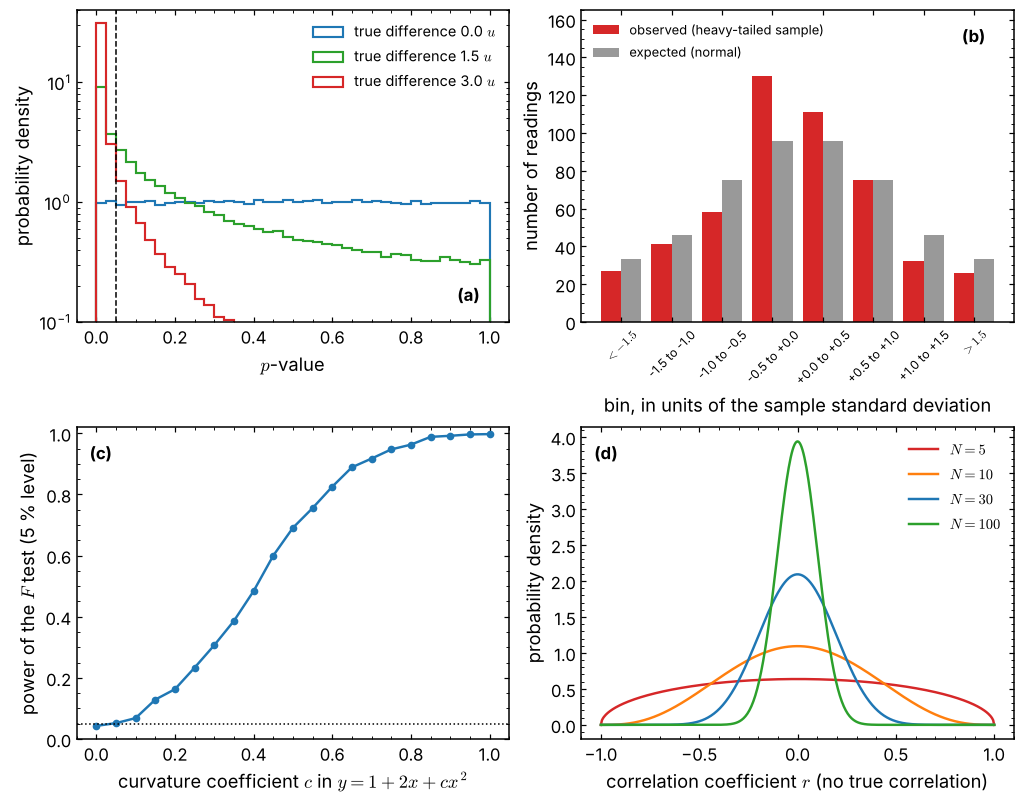

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
bins = np.linspace(0, 1, 41)
for shift, c in ((0.0, "C0"), (1.5, "C2"), (3.0, "C3")):
    ax.hist(p_values[shift], bins=bins, density=True, histtype="step", lw=1.4, color=c,
            label=f"true difference {shift:.1f} $u$")
ax.axvline(0.05, color="k", ls="--", lw=1)
ax.set_yscale("log"); ax.set_ylim(0.1, 40)
ax.set_xlabel("$p$-value"); ax.set_ylabel("probability density")
ax.legend(loc="upper right"); ep.panel_label(ax, "(a)", y=0.12, x=0.88)

ax = axes[0, 1]
O, E, c2, nu, p = chi2_normal_test(x_t, edges_z)
centres = np.arange(O.size)
ax.bar(centres - 0.2, O, width=0.4, color="C3", label="observed (heavy-tailed sample)")
ax.bar(centres + 0.2, E, width=0.4, color="0.6", label="expected (normal)")
labels_b = ["$<-1.5$"] + [f"{lo:+.1f} to {hi:+.1f}" for lo, hi in zip(edges_z[:-1], edges_z[1:])] + ["$>1.5$"]
ax.set_xticks(centres); ax.set_xticklabels(labels_b, rotation=45, fontsize=8)
ax.tick_params(axis="x", which="minor", bottom=False, top=False)
ax.set_xlabel(r"bin, in units of the sample standard deviation"); ax.set_ylabel("number of readings")
ax.set_ylim(0, 165); ax.legend(loc="upper left", fontsize=8.5); ep.panel_label(ax, "(b)", x=0.88)

ax = axes[1, 0]
ax.plot(curv, power, "o-", color="C0", ms=4)
ax.axhline(0.05, color="k", ls=":", lw=1)
ax.set_xlabel(r"curvature coefficient $c$ in $y = 1 + 2x + cx^2$"); ax.set_ylabel("power of the $F$ test (5 % level)")
ax.set_ylim(0, 1.02); ep.panel_label(ax, "(c)")

ax = axes[1, 1]
rr = np.linspace(-1, 1, 401)
for N, c in ((5, "C3"), (10, "C1"), (30, "C0"), (100, "C2")):
    # density of r for independent normal x, y
    dens = (1 - rr**2)**((N - 4) / 2)
    dens /= np.trapezoid(dens, rr) if hasattr(np, 'trapezoid') else np.trapz(dens, rr)
    ax.plot(rr, dens, color=c, label=f"$N = {N}$")
ax.set_xlabel("correlation coefficient $r$ (no true correlation)"); ax.set_ylabel("probability density")
ax.legend(loc="upper right"); ep.panel_label(ax, "(d)")
plt.show()

**(a)** Distribution of $p$-values: uniform when $H_0$ is true (blue),
piled up near zero when it is false. **(b)** The $\chi^2$ test of Section
8.3 for the heavy-tailed sample. **(c)** Power of the $F$ test for a
quadratic term with ten points of noise 0.05. **(d)** Distribution of the
correlation coefficient of uncorrelated data for several sample sizes.

## Summary

* A $p$-value is the probability of data at least as extreme as observed if
  $H_0$ is true; it is not the probability that $H_0$ is true.
* Non-significance means little without power; significance means little
  without the size of the effect.
* Use $t$, not $z$, when the uncertainties come from small samples.
* The $\chi^2$ test compares data with a distribution or a model; count the
  degrees of freedom carefully, and know that $\chi^2_\nu$ scatters by
  $\sqrt{2/\nu}$.
* The $F$ test decides whether extra parameters are justified.
* $r$ tests for the presence of a linear relation, not for agreement.
* Report the number of tests made.

## Exercises

1. Two thermometers are compared at 12 temperatures; the standard
   deviations of their readings about the mean are 0.21 K and 0.13 K. Is
   the second one significantly more precise?
2. Repeat the $\chi^2$ test of Section 8.3 on 1000 independent heavy-tailed
   samples of 200 readings. What fraction is rejected? With 1000 readings
   per sample?
3. Simulate data from a straight line and apply the $F$ test for a quadratic
   term many times. Verify that it rejects the straight line in 5 % of cases.
4. A student finds $r = 0.995$ between the readings of a new and a reference
   thermometer and concludes that the new one is accurate. What should be
   computed instead?
5. A peak search tests 200 independent channels at the 3σ level. How many
   false peaks are expected? At what local significance should a peak be
   claimed so that the global false-alarm probability is 1 %?

---

**Previous:** [7. Estimators and maximum likelihood](07_estimators_and_maximum_likelihood.ipynb) &nbsp;·&nbsp; **Next:** [9. Outliers and the rejection of data](09_outliers_and_data_rejection.ipynb)